# Data Visualization

In [164]:
# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt

## Model Comparison

In [165]:
import pandas as pd
import matplotlib.pyplot as plt

# Function to read CSV files, calculate column means and stdev, and plot the data with shaded areas
def read_and_plot(file_paths, labels, title, path='pics/dummy.png'):
    plt.figure(figsize=(12, 6))
    final_mean = {}
    
    # Loop through each file, calculate the mean and std, and plot it
    for i, file in enumerate(file_paths):
        # Read the CSV file into a pandas DataFrame
        df = pd.read_csv(file, header=None)
        
        # The first column is the label, ignore it for calculation
        data = df.iloc[:, 1:]
        
        # Calculate the mean and standard deviation of each column
        column_means = data.mean(axis=0)
        column_stds = data.std(axis=0)
        
        # Create a range for epochs to ensure consistent x-values
        x = range(len(column_means))
        
        # Plot the mean values as a line
        plt.plot(x, column_means, marker='o', label=labels[i])
        
        # Plot the shaded area for stdev around the mean
        plt.fill_between(x, column_means - column_stds, column_means + column_stds, 
                         alpha=0.2)
        
        # Store the final mean value for each model
        final_mean[labels[i]] = column_means[len(column_means)-1]
    
    # Add title and labels with increased font size
    plt.title(title, fontsize="32")
    plt.xlabel('Epoch', fontsize="32")
    plt.ylabel('Mean Accuracy', fontsize="32")
    
    # Increase tick label font size
    plt.xticks(fontsize="24")
    plt.yticks(fontsize="24")
    
    # Show legend to distinguish between the lines
    plt.legend(fontsize="24")
    
    # Display the plot
    plt.savefig(path, format='png')
    plt.show()

    return final_mean


### IP-Hardness Dataset

Avg. training accuracy

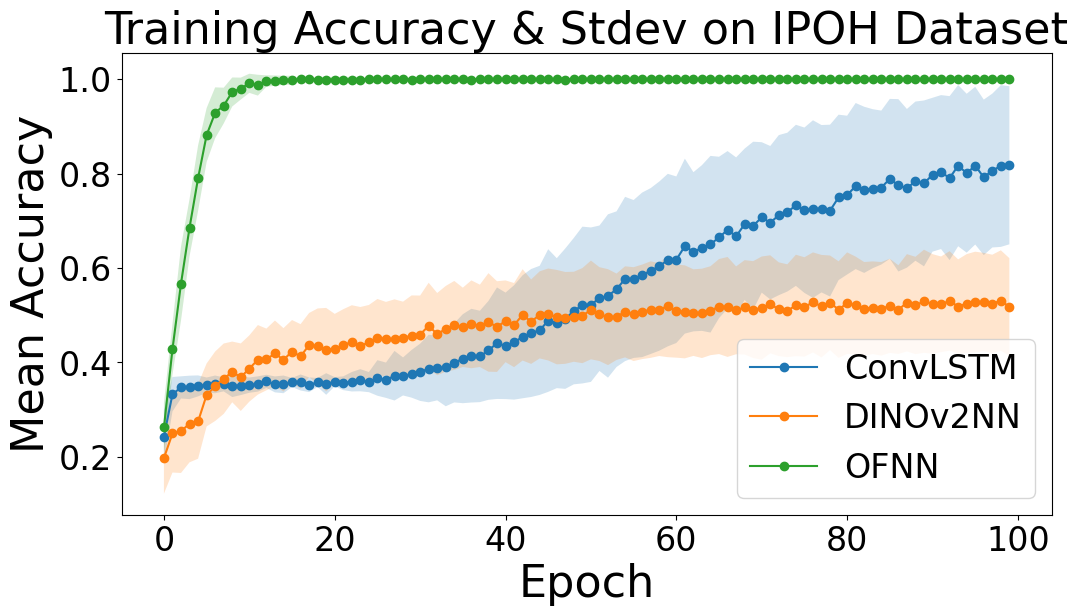

{'ConvLSTM': 0.8159999972581864, 'DINOv2NN': 0.5312000000476838, 'OFNN': 1.0}

In [166]:


# File paths and corresponding labels
file_paths = [
    'metrics/Comp_Model_Aug_11_hardness_ConvLSTM_train_accuracy_history.csv',
    'metrics/Comp_Model_Aug_12_hardness_DINOKeras_train_accuracy_history.csv',
    'metrics/Comp_Model_Aug_11_hardness_OpticalFlowNN_train_accuracy_history.csv'
]

labels = ['ConvLSTM', 'DINOv2NN', 'OFNN']
# Call the function with the file paths and labels
read_and_plot(file_paths, labels, "Training Accuracy & Stdev on IPOH Dataset", path='pics/comp_train_acc_iph.png')

Avg. validation accuracy

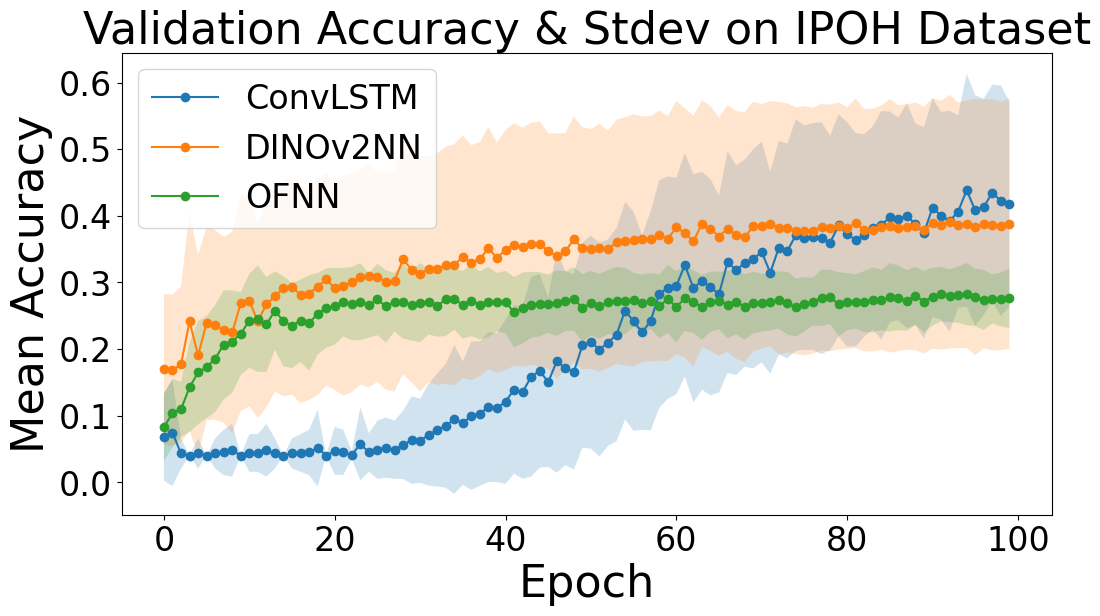

{'ConvLSTM': 0.4224000018835068,
 'DINOv2NN': 0.38479998871684074,
 'OFNN': 0.2743999969959259}

In [167]:
# File paths and corresponding labels
file_paths = [
    'metrics\Comp_Model_Aug_11_hardness_ConvLSTM_val_accuracy_history.csv',
    'metrics\Comp_Model_Aug_12_hardness_DINOKeras_val_accuracy_history.csv',
    'metrics\Comp_Model_Aug_11_hardness_OpticalFlowNN_val_accuracy_history.csv'
]



labels = ['ConvLSTM', 'DINOv2NN', 'OFNN']

# Call the function with the file paths and labels
read_and_plot(file_paths, labels, "Validation Accuracy & Stdev on IPOH Dataset", path='pics/comp_val_acc_iph.png')

### Yuan Dataset

Avg. training accuracy

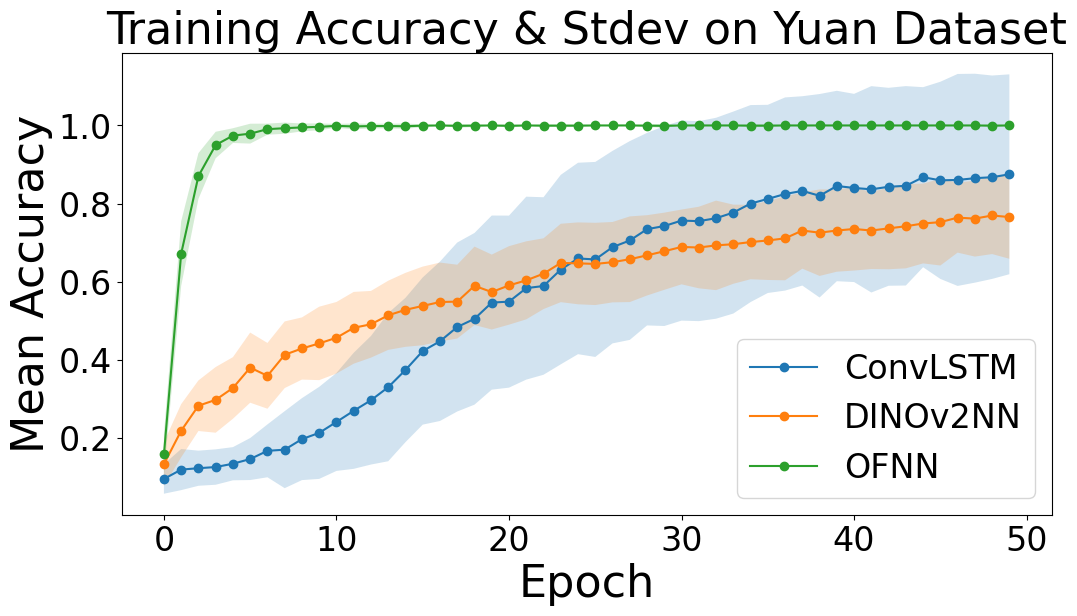

{'ConvLSTM': 0.8675000035762787,
 'DINOv2NN': 0.7695000022649765,
 'OFNN': 0.9995000004768372}

In [168]:
# File paths and corresponding labels
file_paths = [
    'metrics/Comp_Model_Aug_10_final_yuan_ConvLSTM_train_accuracy_history.csv',
    'metrics/Comp_Model_Aug_12_yuan_DINOKeras_train_accuracy_history.csv',
    'metrics/Comp_Model_Aug_10_final_yuan_OpticalFlowNN_train_accuracy_history.csv'
]

labels = ['ConvLSTM', 'DINOv2NN', 'OFNN']

# Call the function with the file paths and labels
read_and_plot(file_paths, labels, "Training Accuracy & Stdev on Yuan Dataset", path='pics/comp_train_acc_yuan.png')

Avg. validation accuracy

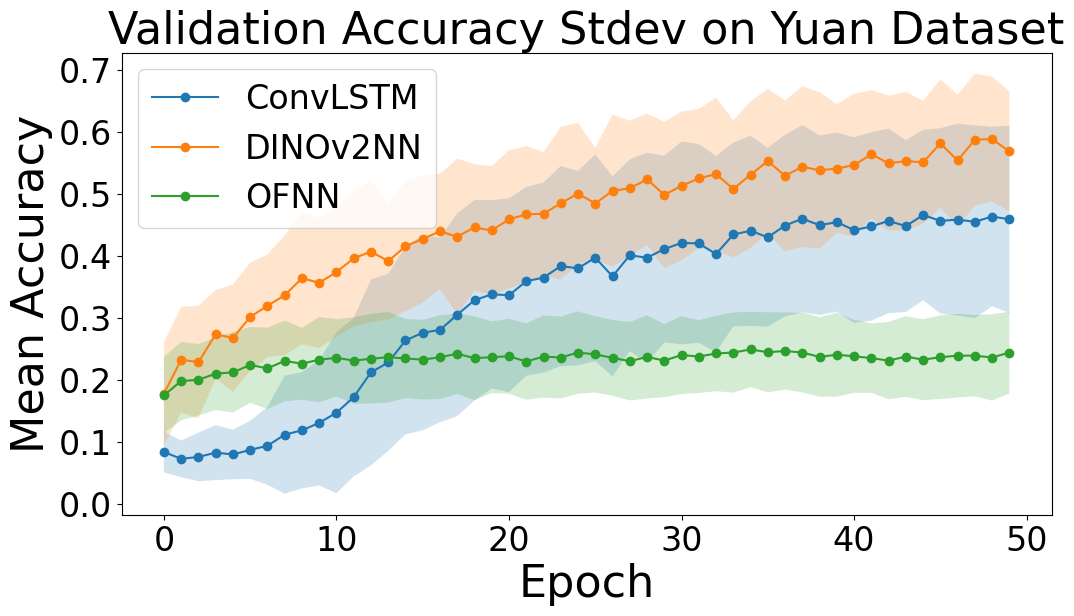

{'ConvLSTM': 0.46349999770522116,
 'DINOv2NN': 0.5884999960660935,
 'OFNN': 0.23600000195205212}

In [169]:
# File paths and corresponding labels
file_paths = [
    'metrics/Comp_Model_Aug_10_final_yuan_ConvLSTM_val_accuracy_history.csv',
    'metrics/Comp_Model_Aug_12_yuan_DINOKeras_val_accuracy_history.csv',
    'metrics/Comp_Model_Aug_10_final_yuan_OpticalFlowNN_val_accuracy_history.csv'
]

labels = ['ConvLSTM', 'DINOv2NN', 'OFNN']

# Call the function with the file paths and labels
read_and_plot(file_paths, labels, "Validation Accuracy Stdev on Yuan Dataset", path='pics/comp_val_acc_yuan.png')

## Adaptive Sampling 

In [170]:
import pandas as pd
import matplotlib.pyplot as plt

def plot_metrics_for_strats(filename, strats, metric, path='pics/dummy.png', title='no title'):
    # 0. Read the file
    df = pd.read_csv(filename, header=None)

    plt.figure(figsize=(14, 8))  # Increase the figure size to accommodate the table

    for strat in strats:
        # 1. Filter rows where the first column contains the string `strat`
        filtered_df = df[df[0].str.contains(strat, na=False)]

        # 2. Compute the mean and standard deviation of each column (excluding the first one, which is the row identifier)
        mean_values = filtered_df.iloc[:, 1:].mean()
        std_values = filtered_df.iloc[:, 1:].std()

        # 3. Plot a line for the current strat
        plt.plot(range(len(mean_values)), mean_values, marker='o', label=strat)

        # 4. Shade the standard deviation area around the line
        plt.fill_between(range(len(mean_values)),
                         mean_values - std_values, 
                         mean_values + std_values, 
                         alpha=0.2)  # Use transparency to shade

        # Prepare the DataFrame for display as a table
        mean_table = pd.DataFrame(mean_values, columns=[strat])
        print(f"Mean values for {strat}:")
        print(mean_table)
        print("\n")

    # Finalize the plot
    plt.title(title, fontsize=32)
    plt.xlabel('Iterations', fontsize=32)
    plt.ylabel(metric, fontsize=32)
    plt.xticks(range(len(mean_values)), fontsize=24)  # Set X-axis ticks to match the iteration indices
    plt.yticks(fontsize=24)
    plt.legend(fontsize=24)
    plt.grid(True)
    plt.savefig(path, format='png')
    plt.show()

# Example usage:
# strats = ['entropy_leave_[87]_out', 'another_strat']
# plot_metrics_for_strats('data.csv', strats, 'Some Metric')


# IP-Hardness Dataset w/ ConvLSTM

Mean values for entropy:
    entropy
1  0.572000
2  0.715789
3  0.805263
4  0.873684
5  0.857895
6  0.857895


Mean values for variance:
   variance
1  0.548000
2  0.756098
3  0.839024
4  0.819512
5  0.892683
6  0.887805


Mean values for random:
     random
1  0.564000
2  0.655814
3  0.744186
4  0.800000
5  0.753488
6  0.832558




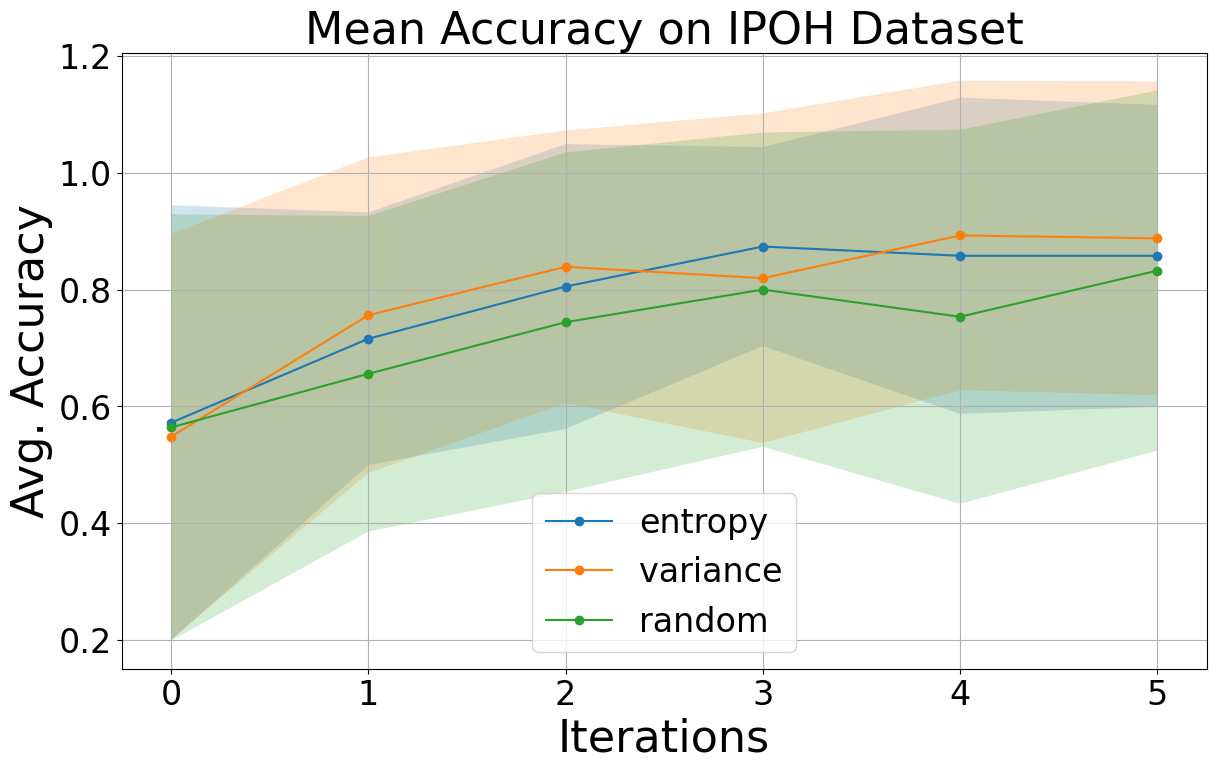

In [171]:
strats = ['entropy', 'variance', 'random']
plot_metrics_for_strats('metrics\exp\Final_exp_hardness_ConvLSTM_acc_comp_history.csv', strats, 'Avg. Accuracy', path='pics/IPH_Acc.png', title='Mean Accuracy on IPOH Dataset')

Mean values for entropy:
    entropy
1  0.112600
2  0.082368
3  0.058211
4  0.033368
5  0.042316
6  0.038737


Mean values for variance:
   variance
1  0.122360
2  0.058049
3  0.040000
4  0.048927
5  0.028195
6  0.029122


Mean values for random:
     random
1  0.123080
2  0.088744
3  0.063070
4  0.045209
5  0.070698
6  0.049116




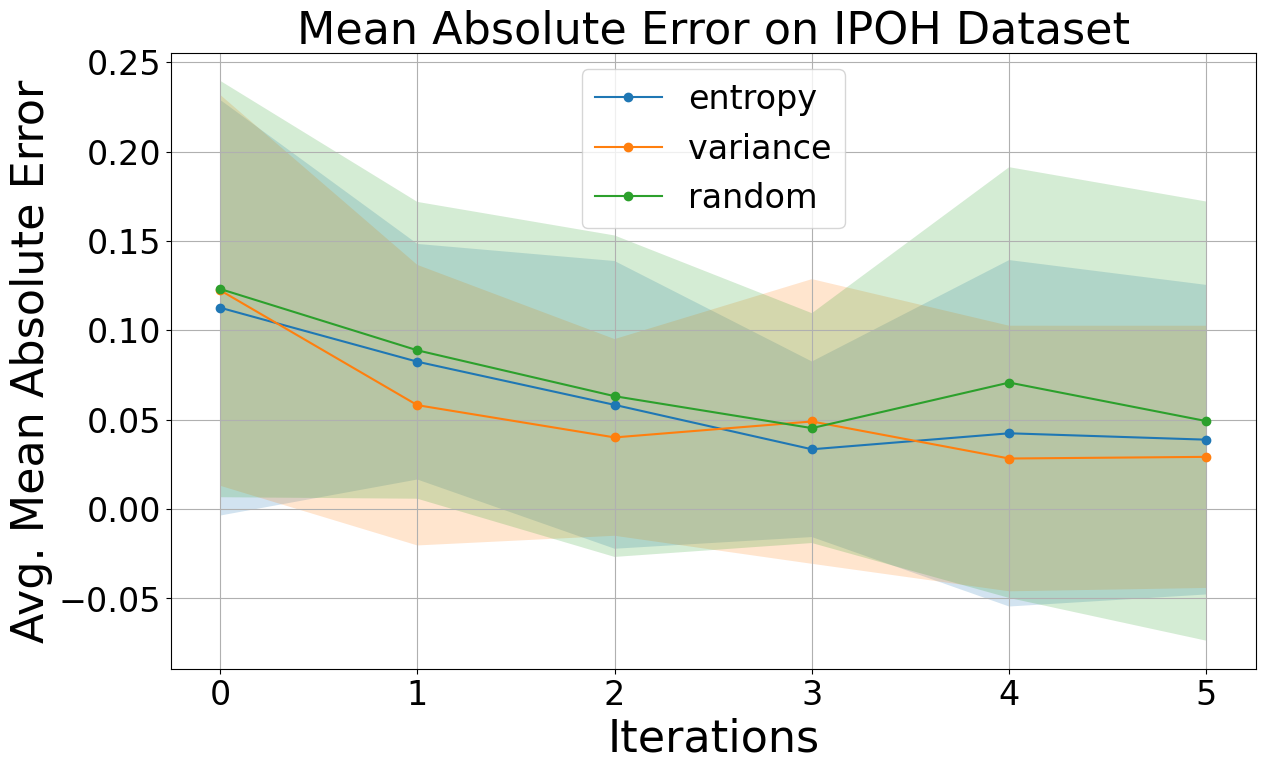

In [172]:
plot_metrics_for_strats('metrics\exp\Final_exp_hardness_ConvLSTM_abs_diff_comp_history.csv', strats, 'Avg. Mean Absolute Error', path='pics/IPH_MAE.png', title='Mean Absolute Error on IPOH Dataset')

## Yuan Dataset w/ DinoV2NN

Mean values for entropy:
    entropy
1  0.697778
2  0.800000
3  0.826667
4  0.857778
5  0.915556
6  0.897778


Mean values for variance:
   variance
1  0.684444
2  0.795556
3  0.875556
4  0.915556
5  0.946667
6  0.968889


Mean values for random:
     random
1  0.693333
2  0.764444
3  0.768889
4  0.786667
5  0.826667
6  0.884444




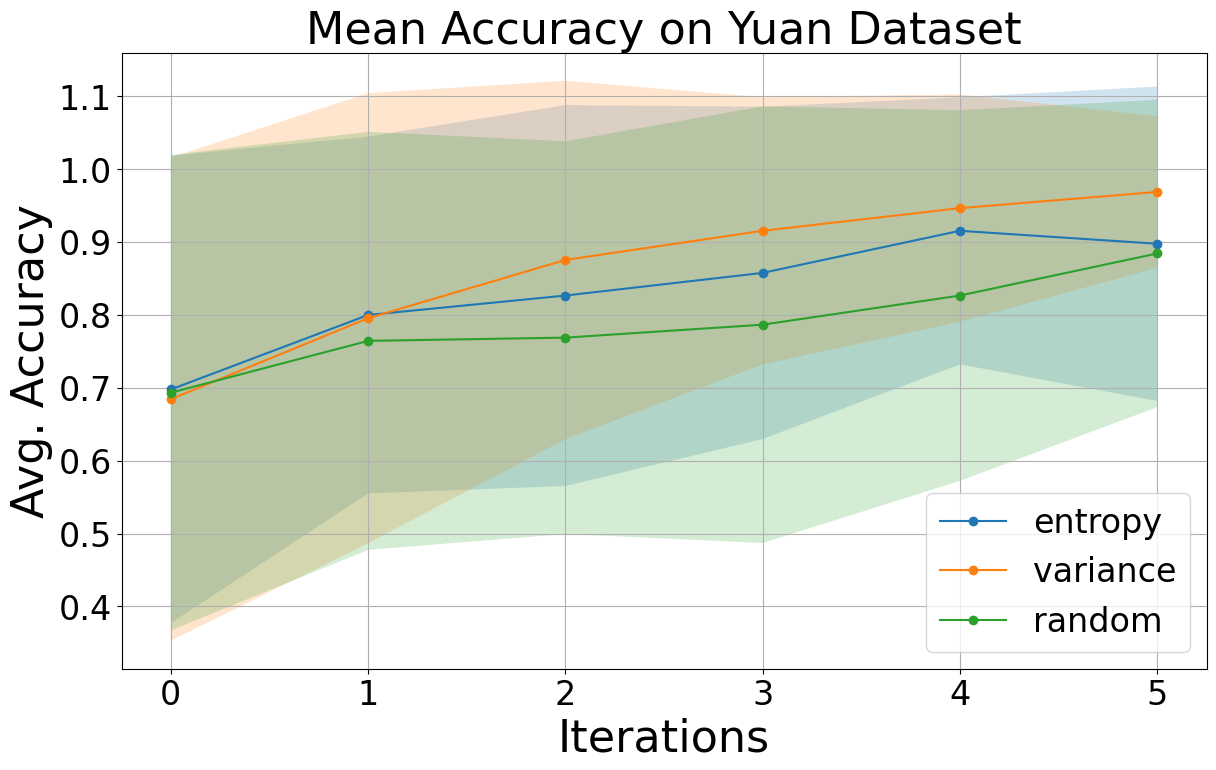

In [173]:
strats = ['entropy', 'variance', 'random']
plot_metrics_for_strats('metrics\exp\Final_exp_Aug_12_yuan_DINOKeras_acc_comp_history.csv', strats, 'Avg. Accuracy', path='pics/Yuan_Acc.png', title='Mean Accuracy on Yuan Dataset')

Mean values for entropy:
    entropy
1  3.671111
2  2.217778
3  1.986667
4  1.391111
5  0.844444
6  0.973333


Mean values for variance:
   variance
1  3.511111
2  2.071111
3  1.297778
4  1.115556
5  0.595556
6  0.506667


Mean values for random:
     random
1  3.640000
2  2.724444
3  2.617778
4  2.248889
5  2.666667
6  1.377778




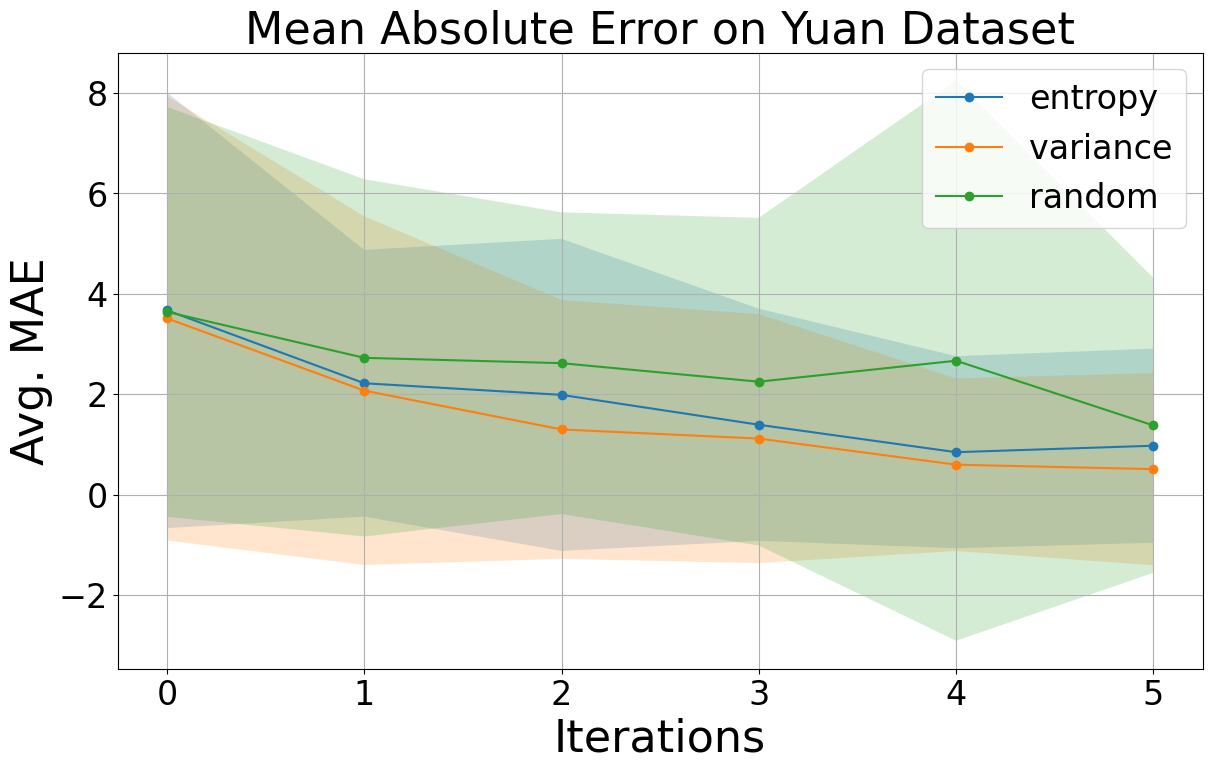

In [174]:
plot_metrics_for_strats('metrics\exp\Final_exp_Aug_12_yuan_DINOKeras_abs_diff_comp_history.csv', strats, 'Avg. MAE', path='pics/Yuan_MAE.png', title='Mean Absolute Error on Yuan Dataset')


## Uncertainty

Mean values for entropy:
    entropy
1  0.409084
2  0.292593
3  0.179470
4  0.145584
5  0.188642


Mean values for variance:
   variance
1  0.463200
2  0.275080
3  0.199107
4  0.233598
5  0.181837


Mean values for random:
     random
1  0.458152
2  0.342288
3  0.318055
4  0.253523
5  0.257998




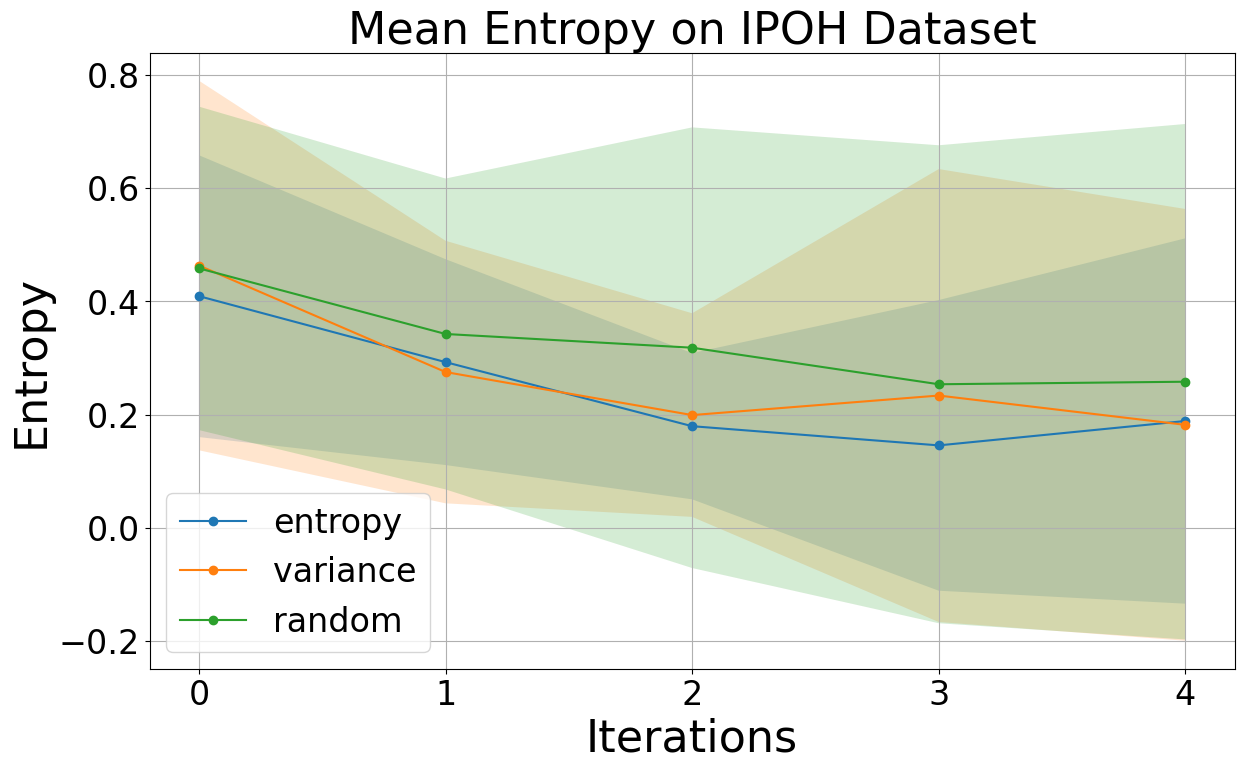

In [175]:
plot_metrics_for_strats('metrics\exp\Final_exp_hardness_ConvLSTM_avg_entropy_history.csv', strats, 'Entropy', path='pics/IPH_Entropy.png', title='Mean Entropy on IPOH Dataset')


Mean values for entropy:
    entropy
1  0.011620
2  0.018229
3  0.018095
4  0.012403
5  0.011250


Mean values for variance:
   variance
1  0.013810
2  0.016008
3  0.013770
4  0.011727
5  0.008647


Mean values for random:
     random
1  0.013115
2  0.018103
3  0.017347
4  0.014095
5  0.010688




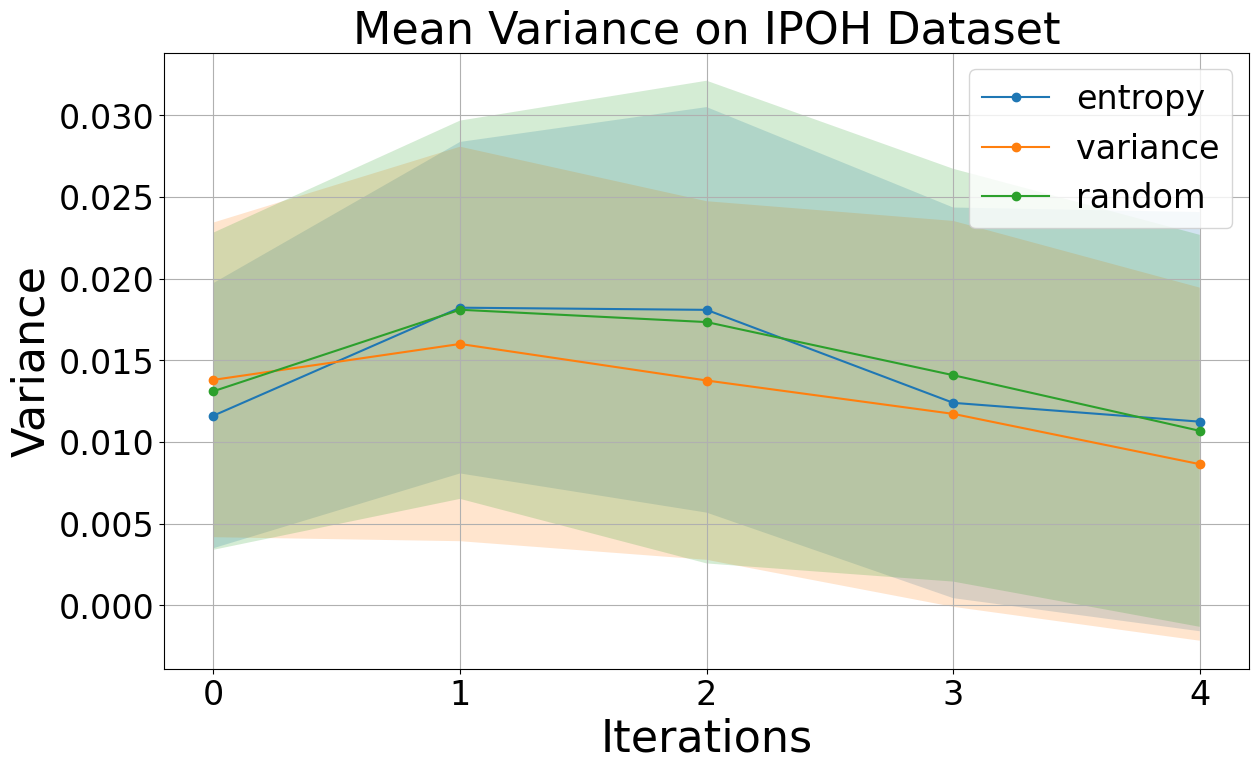

In [176]:
plot_metrics_for_strats('metrics\exp\Final_exp_hardness_ConvLSTM_avg_variance_history.csv', strats, 'Variance', path='pics/IPH_Variance.png', title='Mean Variance on IPOH Dataset')


Mean values for entropy:
    entropy
1  0.354880
2  0.278977
3  0.219235
4  0.172345
5  0.137521


Mean values for variance:
   variance
1  0.351882
2  0.256277
3  0.180998
4  0.138835
5  0.121578


Mean values for random:
     random
1  0.311672
2  0.318269
3  0.246776
4  0.196927
5  0.188815




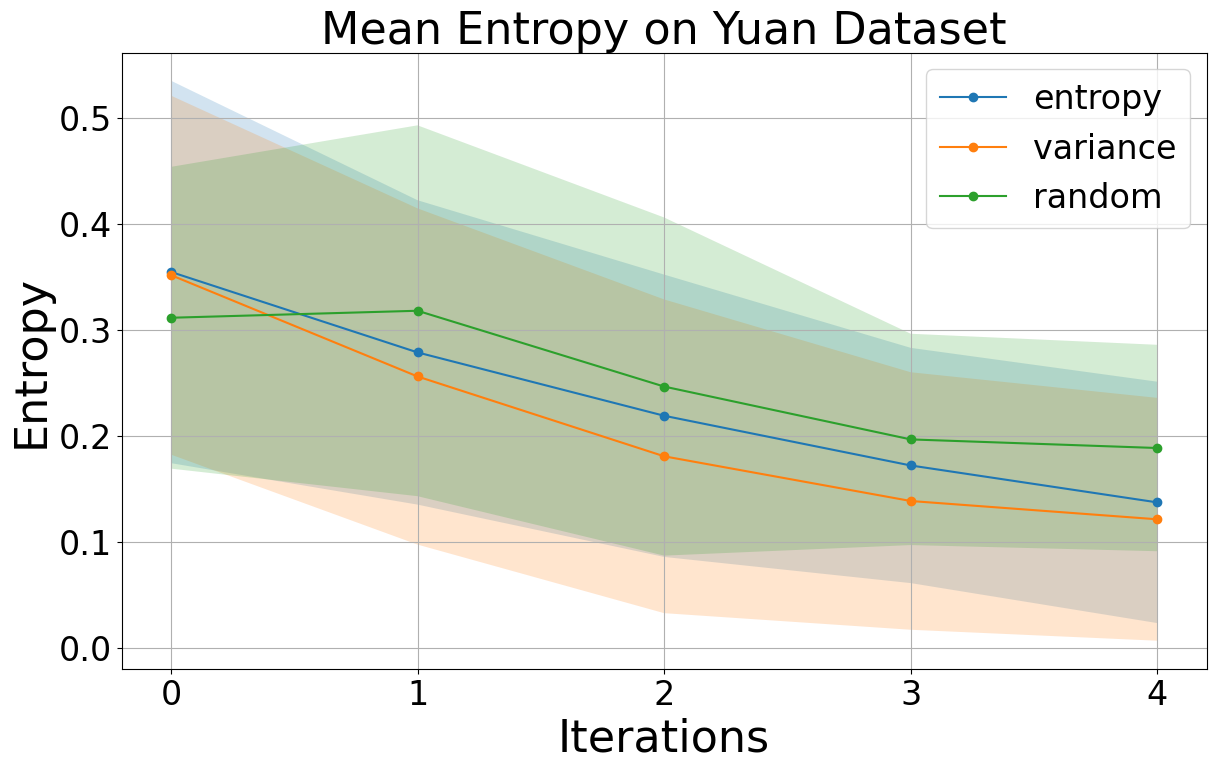

In [177]:
plot_metrics_for_strats('metrics\exp\Final_exp_Aug_12_yuan_DINOKeras_avg_entropy_history.csv', strats, 'Entropy', path='pics/Yuan_Entropy.png', title='Mean Entropy on Yuan Dataset')


Mean values for entropy:
    entropy
1  0.012927
2  0.012395
3  0.012613
4  0.012565
5  0.009592


Mean values for variance:
   variance
1  0.011808
2  0.011865
3  0.009235
4  0.008950
5  0.007782


Mean values for random:
     random
1  0.012963
2  0.012940
3  0.013344
4  0.014796
5  0.016730




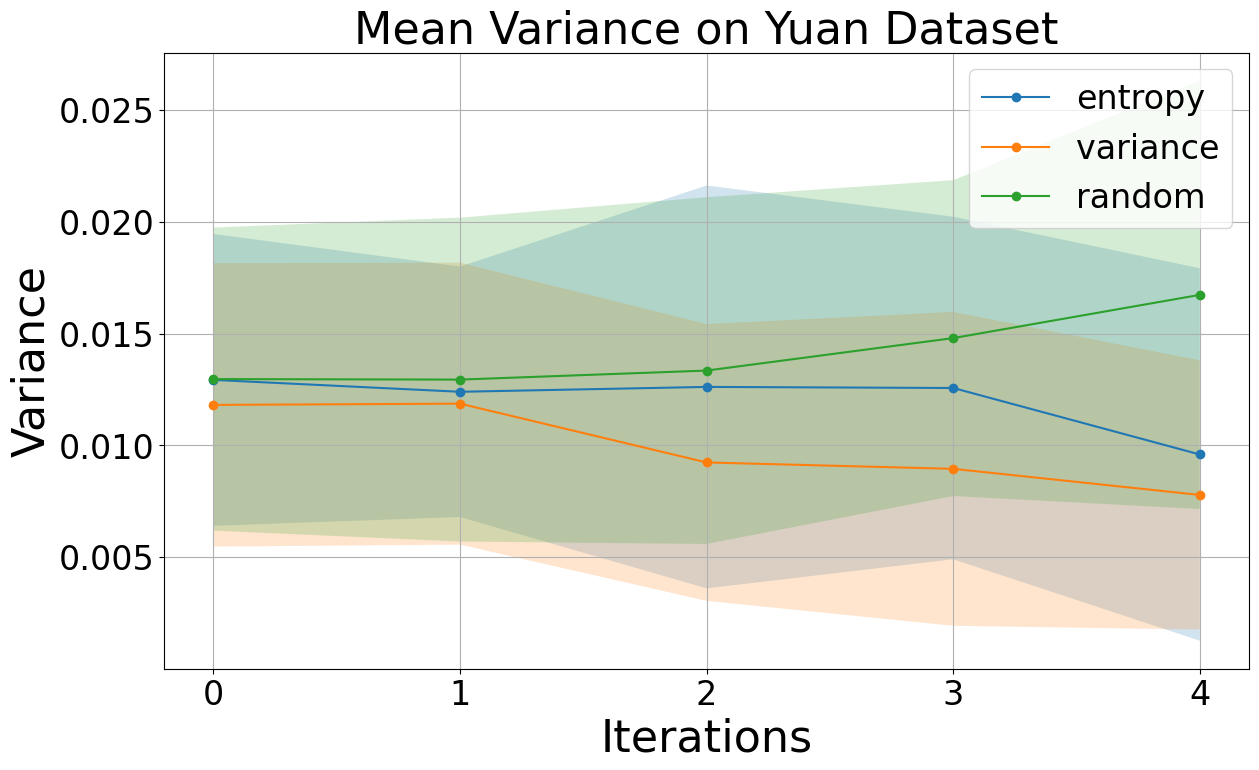

In [178]:
plot_metrics_for_strats('metrics\exp\Final_exp_Aug_12_yuan_DINOKeras_avg_variance_history.csv', strats, 'Variance', path='pics/Yuan_Variance.png', title='Mean Variance on Yuan Dataset')


## Domain Expansion

C:\Users\bnkrg\AppData\Local\Temp\ipykernel_22216\1962203830.py:27: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.plot(x_smooth, y_smooth, label=row[0])


<module 'matplotlib.pyplot' from 'c:\\Python310\\lib\\site-packages\\matplotlib\\pyplot.py'>

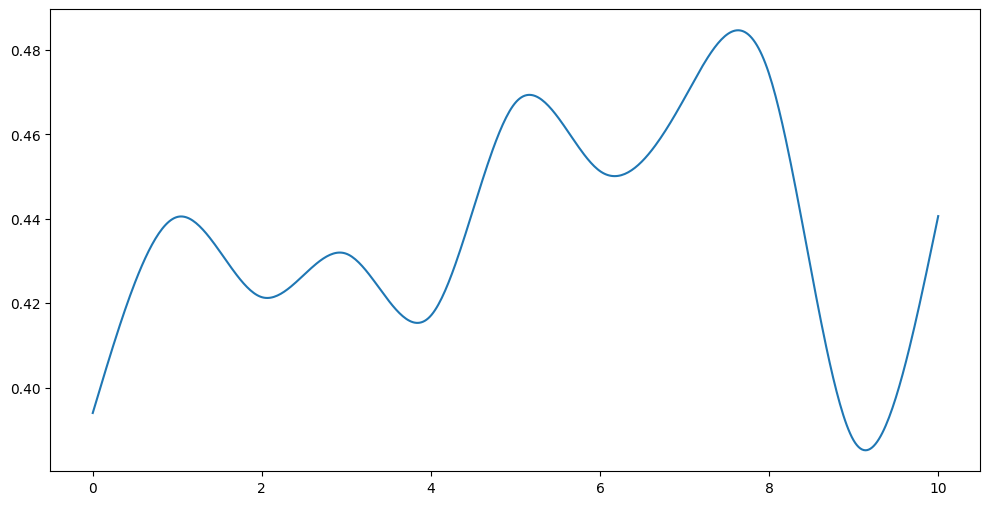

In [179]:
# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import CubicSpline

# Function to interpolate using cubic splines and plot each row as a separate curve
def read_and_plot_smoothed_curves(csv_file):
    # Read the CSV file into a pandas DataFrame
    df = pd.read_csv(csv_file)
    
    plt.figure(figsize=(12, 6))
    
    for index, row in df.iterrows():
        # Extract iteration indices and values
        x = np.arange(len(row[1:]))  # x-coordinates (iteration indices)
        y = row[1:].values          # y-coordinates (values)
        
        # Perform cubic spline interpolation
        cs = CubicSpline(x, y, bc_type='natural')
        
        # Generate a smooth curve
        x_smooth = np.linspace(x.min(), x.max(), 500)  # 500 points for smooth curve
        y_smooth = cs(x_smooth)
        
        # Plot the smooth curve
        plt.plot(x_smooth, y_smooth, label=row[0])
        return plt
    
    plt.title('Mean Accuracy Each Iteration')
    plt.xlabel('Iteration Index')
    plt.ylabel('Mean Accuracy')
    plt.legend()
    plt.show()

# Example usage: replace 'data.csv' with your actual CSV file path
read_and_plot_smoothed_curves('domain_expansion.csv')
